# Fitting simulations with Piff (`psf_fomo.piff_simfit`)

This notebook fits simulated stars with Piff and compares the fitted PSF model with the truth.
Every fit follows the same pattern:

1. **describe the model** with a `PiffFitConfig` (which Piff components, fitted or fixed),
2. **set up the run** with a `PiffSimFit` (simulation, SCA, reserve stars, diagnostics),
3. **run** it, which returns a `PiffSimFitResult` (fitted PSF, star tables, moments, plots).

Only Piff's own model components are used: `RomanOptics` (GalSim's Roman PSF with fitted
extra aberrations), the fixed charge-diffusion kernel (MTF, a `GaussianMixture`),
`GaussianBlur` and `PixelGrid`.

**Color.** Simulations are chromatic by default (each star drawn through the filter with its
SED, `01_simulation.ipynb`), while `PiffFitConfig` fits a **monochromatic** `RomanOptics` by
default: the PSF at the filter's effective wavelength. Piff can fit a chromatic
`RomanOptics` only when it is the whole model, without the MTF or any other component.
Parts 1 and 2 use monochromatic simulations, so that model and simulation match; part 3 fits
a chromatic simulation with the monochromatic models.

Units and definitions are in [`docs/conventions.md`](../docs/conventions.md); all options are
in [`docs/piff_simfit.md`](../docs/piff_simfit.md). Moments are measured as in `02_moments.ipynb`.
Nothing in this notebook is written to disk; the cells that save are commented out.

Note that Piff can take some time to run, so its normal if some cells take minutes or tens of minutes to run.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from cycler import cycler
from matplotlib.ticker import MaxNLocator
from astropy.table import Table
from IPython.display import display

from psf_fomo.sim import RomanSimulation
from psf_fomo.piff_simfit import PiffFitConfig, PiffSimFit
from psf_fomo.piff_simfit.plotting import mean_images, mean_oversampled
from psf_fomo.reference import comparison_table

**Plot style.** The same style as `02_moments.ipynb`, with one color per model.

In [2]:
BACKGROUND, TEXT, MUTED, GRID = "white", "black", "dimgray", "gainsboro"
COLOR_CYCLE = ["royalblue", "darkorange", "mediumseagreen", "goldenrod", "hotpink", "green",
               "slateblue", "crimson"]
TRUTH_COLOR = MUTED
MODEL_COLORS = {"pinned": "darkorange", "realistic": "royalblue"}

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": BACKGROUND, "axes.facecolor": BACKGROUND,
    "font.size": 12, "text.color": TEXT,
    "axes.titlesize": 13, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.titlepad": 10, "axes.labelsize": 12, "axes.labelcolor": MUTED,
    "axes.edgecolor": "darkgray", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 11, "ytick.labelsize": 11,
    "legend.frameon": False, "legend.fontsize": 10,
    "lines.linewidth": 2, "lines.markersize": 7, "errorbar.capsize": 0,
    "axes.prop_cycle": cycler(color=COLOR_CYCLE),
})

**Helpers for the plots and tables** (the Piff calls are written out in the sections below):

- `plot_residuals`: mean image residuals over the fit stars, native (data − model) and
  oversampled ×5 (model − truth), as a fraction of the peak, one row per model;
- `plot_moments`: histograms of `T`, `e1`, `e2` of the truth and of each model, native
  (`wmom` 0.4″) and oversampled (`hsm`);
- `moment_errors`: mean model − truth moments (± error on the mean) per model;
- `fmt` rounds the numbers of a table for display.

In [3]:
NATIVE = ("truth_native", "wmom_0.4", "native, wmom 0.4″")
OVERSAMPLED = ("truth_os", "hsm", "oversampled, hsm")
QUANTITIES = {"T": "T [arcsec²]", "e1": "e1", "e2": "e2"}


def _number(v):
    # 4 decimals above 1, 4 significant digits from 1e-3 to 1, scientific notation otherwise.
    if v == 0 or 1 <= abs(v) < 1e4:
        return f"{v:.4f}"
    return f"{v:.4g}" if 1e-3 <= abs(v) < 1 else f"{v:.3e}"


def fmt(table):
    for name in table.colnames:
        if table[name].dtype.kind == "f":
            table[name].info.format = _number
    return table


def good_moments(res, comparison, algorithm):
    m = res.moments
    return m[(m["comparison"] == comparison) & (m["algorithm"] == algorithm) & (m["flag"] == 0)]


def plot_residuals(fits):
    rows = []
    for label, res in fits.items():
        stars, cat = res.selected_stars("fit")
        native = mean_images(res.psf, stars)
        over = mean_oversampled(res.psf, stars, cat, res.sim)
        rows.append((label, native["resid"] / native["data"].max(),
                     over["resid"] / over["truth"].max()))
    lims = [max(np.abs(r[k]).max() for r in rows) for k in (1, 2)]
    fig, axes = plt.subplots(len(rows), 2, figsize=(11, 4.6 * len(rows)), squeeze=False)
    for ax_row, (label, *images) in zip(axes, rows):
        for ax, image, lim, title in zip(ax_row, images, lims,
                                         ("native: data − model", "oversampled: model − truth")):
            im = ax.imshow(image, origin="lower", cmap="RdBu_r", vmin=-lim, vmax=lim)
            fig.colorbar(im, ax=ax, shrink=0.85, label="fraction of the peak")
            ax.set(title=f"{label}, {title}", xticks=[], yticks=[])
            ax.grid(False)
    fig.tight_layout()
    return fig


def bin_edges(values, n_stars):
    # Few stars: about √N bins (5 to 15) over the common range of truth and models.
    n_bins = int(np.clip(round(np.sqrt(n_stars)), 5, 15))
    lo, hi = np.min(values), np.max(values)
    pad = max(0.05 * (hi - lo), 1e-6 * max(abs(lo), abs(hi), 1e-12))
    return np.linspace(lo - pad, hi + pad, n_bins + 1)


def plot_moments(fits, rows=(NATIVE, OVERSAMPLED)):
    fig, axes = plt.subplots(len(rows), 3, figsize=(16, 4.2 * len(rows)), squeeze=False)
    for ax_row, (comparison, algorithm, title) in zip(axes, rows):
        tables = {label: good_moments(res, comparison, algorithm) for label, res in fits.items()}
        truth = next(iter(tables.values()))        # same stars and truth in every fit
        for ax, (q, qlabel) in zip(ax_row, QUANTITIES.items()):
            values = np.concatenate([truth[q + "_ref"]]
                                    + [t[q + "_model"] for t in tables.values()])
            edges = bin_edges(values, len(truth))
            ax.hist(truth[q + "_ref"], bins=edges, color=TRUTH_COLOR, alpha=0.3, label="truth")
            for label, t in tables.items():
                ax.hist(t[q + "_model"], bins=edges, histtype="step", lw=2,
                        color=MODEL_COLORS[label], label=label)
            ax.yaxis.set_major_locator(MaxNLocator(integer=True))
            ax.set(title=f"{title}: {q}", xlabel=qlabel, ylabel="stars")
    axes[0, 0].legend()
    fig.tight_layout()
    return fig


def moment_errors(fits, rows=(NATIVE, OVERSAMPLED)):
    out = []
    for label, res in fits.items():
        for comparison, algorithm, title in rows:
            m = good_moments(res, comparison, algorithm)
            row = {"model": label, "image": title, "n": len(m)}
            for q in ("dT_T", "de1", "de2"):
                values = np.asarray(m[q])
                row[q] = values.mean()
                row[q + "_err"] = values.std(ddof=1) / np.sqrt(len(values))
            out.append(row)
    return fmt(Table(rows=out))

# Part 1: fitting a monochromatic simulation

## 1.1 The simulation

36 stars of magnitude 18 on a grid on SCA 1, each at a random sub-pixel phase, no injected
PSF error. The simulation is monochromatic (`set_chromatic(None)`), like the Piff models
below. The noise is that of an L2 image (`set_noise("roman-L2")`; `01_simulation.ipynb`), so that
Piff's χ² has a noise scale.

In [4]:
def make_sim(chromatic=False, n_stars=36, seed=1):
    s = RomanSimulation(n_stars=n_stars, seed=seed)    # defaults: SCA 1, H158, 1 observation
    s.set_placement("grid")                            # default "random"
    s.set_brightness(mag=18.0)
    s.set_noise("roman-L2")
    if not chromatic:
        s.set_chromatic(None)                          # default: chromatic, flat SED
    return s


sim = make_sim().run()

The full SCA image (red circles: the stars) and a few star stamps:

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


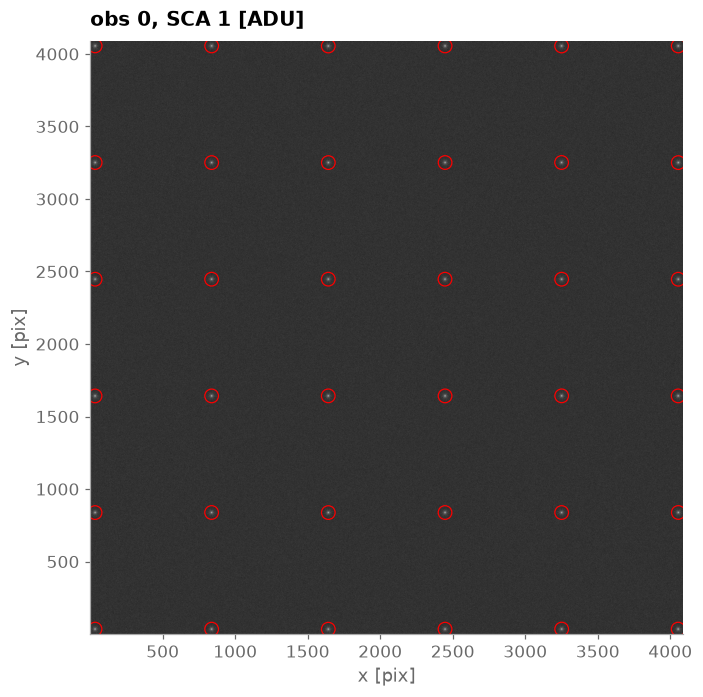

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


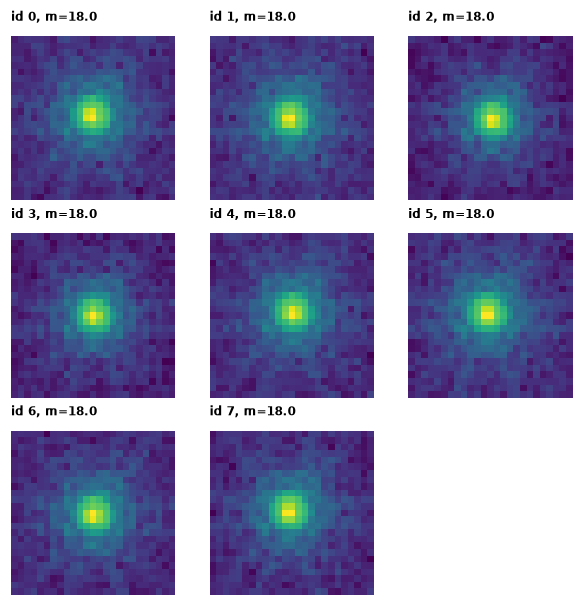

In [5]:
sim.plot_sca(sca=1)
plt.show()
sim.plot_stamps(sca=1, n_max=8)
plt.show()

## 1.2 Two models

**Pinned optics.** The simplest model: `RomanOptics` with the extra aberrations held at zero
(the nominal GalSim Roman PSF) and the fixed MTF. Nothing in the PSF shape is fitted; Piff
fits only the flux and center of each star.

**Realistic model.** `RomanOptics` with the extra Zernikes Z4 … Z11 fitted (one set for the
SCA, with a Gaussian prior), the MTF, a `GaussianBlur` (a fitted Gaussian convolution that
varies linearly across the SCA) and a `PixelGrid` (a fitted 5 × 5 grid of values on the native
pixel scale, added to the rest, also varying linearly).

In [6]:
pinned = PiffFitConfig()          # defaults: free optics Z4…Z22, prior σ 0.05 waves, MTF on,
                              # monochromatic (chromatic=False), no GaussianBlur, no PixelGrid
pinned.set_optics("pinned")   # extra aberrations held at 0

realistic = PiffFitConfig()
realistic.set_optics("free", max_zernike=11, prior_sigma=0.05)   # fit Z4 … Z11 [waves]
realistic.add_kernel("blur", order=1)                            # GaussianBlur, linear in (u, v)
realistic.add_pixelgrid(size=5, scale=0.11, order=1)             # 5 × 5 grid, 0.11″ spacing

Other `PiffFitConfig` settings, with their defaults: `set_mtf(on=True)`,
`set_iterations(max_iter=30, min_iter=2, chisq_thresh=0.1)` (Piff stops when χ² changes by
less than `chisq_thresh` × dof; with noiseless stars use a tiny value),
`set_outliers(chisq_nsigma=None, max_centroid=None)` (no outlier rejection).
`realistic.piff_config("H158")` shows the Piff `psf` configuration that is built.

## 1.3 Fitting

`PiffSimFit` sets up the fit of one SCA. 20 % of the stars are **reserve stars**: they
are not used in the fit, but the model is evaluated and compared with them like with the
others. `set_diagnostics` chooses the moments measured after the fit (section 1.4).

In [7]:
def fit(sim, cfg):
    pv = PiffSimFit(sim, cfg, sca=1)    # defaults: the first SCA, all observations pooled
    pv.set_reserve(frac=0.2, seed=1)        # default frac=0.2, seed=0 (none without the call)
    pv.set_diagnostics(native=("wmom",), wmom_fwhm=(0.4,), oversampled=("hsm",))
    # defaults: native=("wmom", "gauss"), wmom_fwhm=(0.4,), oversampled=("hsm",)
    # Also: pv.set_cuts(min_sep=2.5) (default: stars with a neighbor within 2.5″ are left
    # out), pv.set_verbose(1) (Piff's log; default 0 = errors only).
    return pv.run()                         # save_to=None (default): nothing written


fits = {"pinned": fit(sim, pinned), "realistic": fit(sim, realistic)}

`res.fit_summary` describes the whole fit (χ²/dof, Piff iterations, whether Piff converged,
star counts, run time in seconds); `res.table` has one row per star (position, `reserve`,
Piff's `flag`, `flux_r` = fitted / true flux, fitted center offset `dx`, `dy` [pix],
χ²/dof).

In [8]:
keys = ("chisq_dof", "niter", "converged", "n_stars", "n_reserve", "n_flagged", "seconds")
display(fmt(Table(rows=[{"model": label, **{k: res.fit_summary[k] for k in keys}}
                        for label, res in fits.items()])))
fmt(fits["realistic"].table["star_id", "x", "y", "reserve", "flag", "flux_r", "dx", "dy",
                            "chisq_dof"][:4])

/tmp/ipykernel_359293/3884395944.py:10: FutureWarning: Format strings passed to MaskedConstant are ignored, but in future may error or produce different behavior
  return f"{v:.4g}" if 1e-3 <= abs(v) < 1 else f"{v:.3e}"


model,chisq_dof,niter,converged,n_stars,n_reserve,n_flagged,seconds
str9,float64,int64,bool,int64,int64,int64,float64
pinned,0.9882,2,True,36,7,0,34.3591
realistic,0.9846,2,True,36,7,0,143.6791


star_id,x,y,reserve,flag,flux_r,dx,dy,chisq_dof
,pix,pix,,,,pix,pix,
int64,float64,float64,bool,int64,float64,float64,float64,float64
0,33.7128,34.3136,False,0,1.0106,1.133e-04,-9.897e-04,0.9352
1,837.6425,33.8758,True,0,1.0109,-0.003377,0.001965,1.0315
2,1642.2467,33.7013,False,0,1.0105,0.001429,-0.003268,0.8905
3,2447.0367,33.8799,False,0,1.0156,-0.001062,0.001429,1.0059


## 1.4 How well do the models match the truth?

After the fit, each star's model is compared with the truth (`res.moments`, one row per star
× comparison × algorithm):

| comparison | truth | model | algorithm here |
|---|---|---|---|
| `truth_native` | the noiseless star on the native pixels | the model at the true flux and center | `wmom` 0.4″ |
| `truth_os` | the truth PSF, oversampled ×5 | the model on the same grid | `hsm` |
| `data` | the noisy data stamp | the model at the fitted flux and center | `wmom` 0.4″ |

**Images.** Mean residual over the fit stars, as a fraction of the peak: native (data − model)
and oversampled (model − truth), one row per model, same color scale in each column.

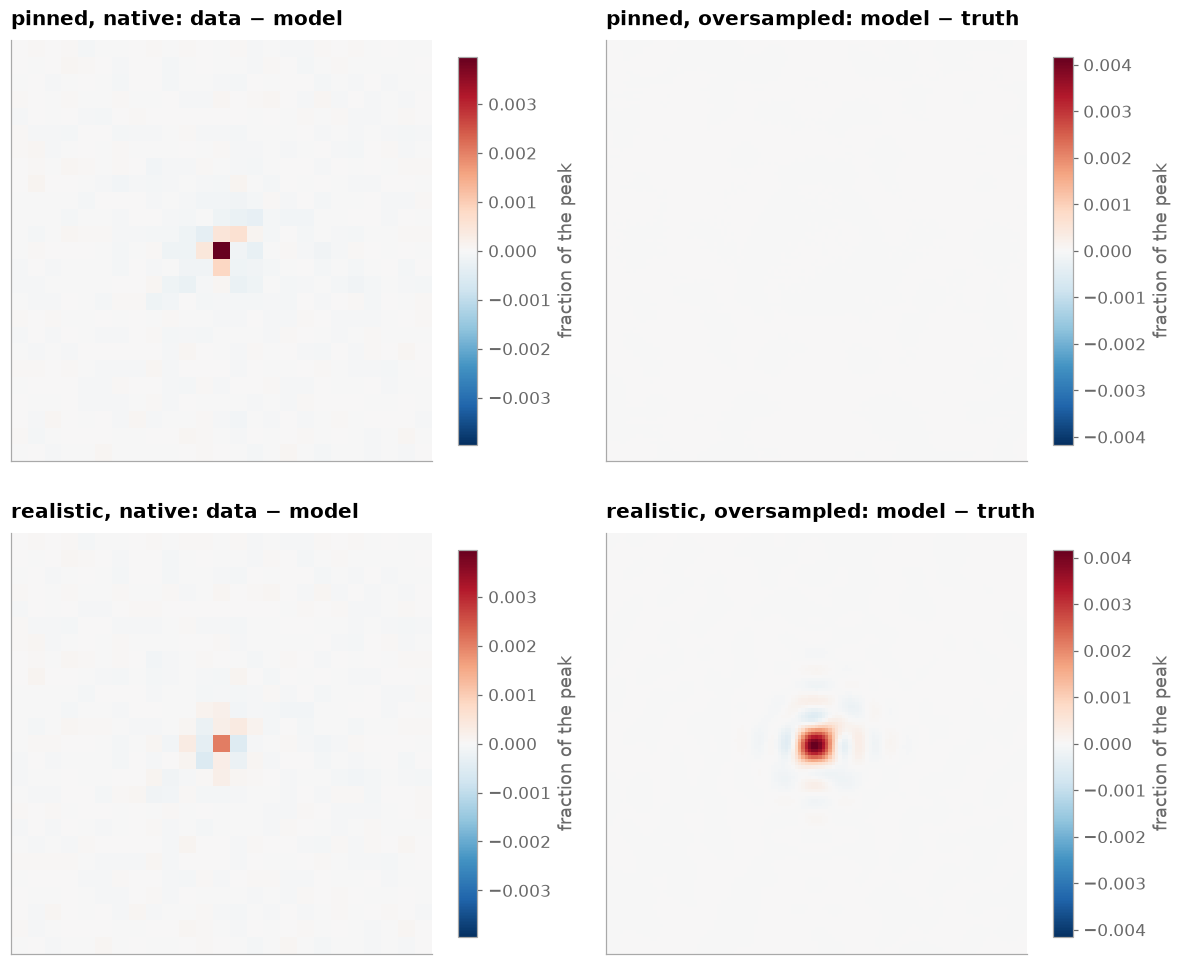

In [9]:
plot_residuals(fits)
plt.show()

**Moments.** `T`, `e1` and `e2` of every star (fit and reserve) for the truth (gray) and the
two models (outlines): native (top) and oversampled (bottom).

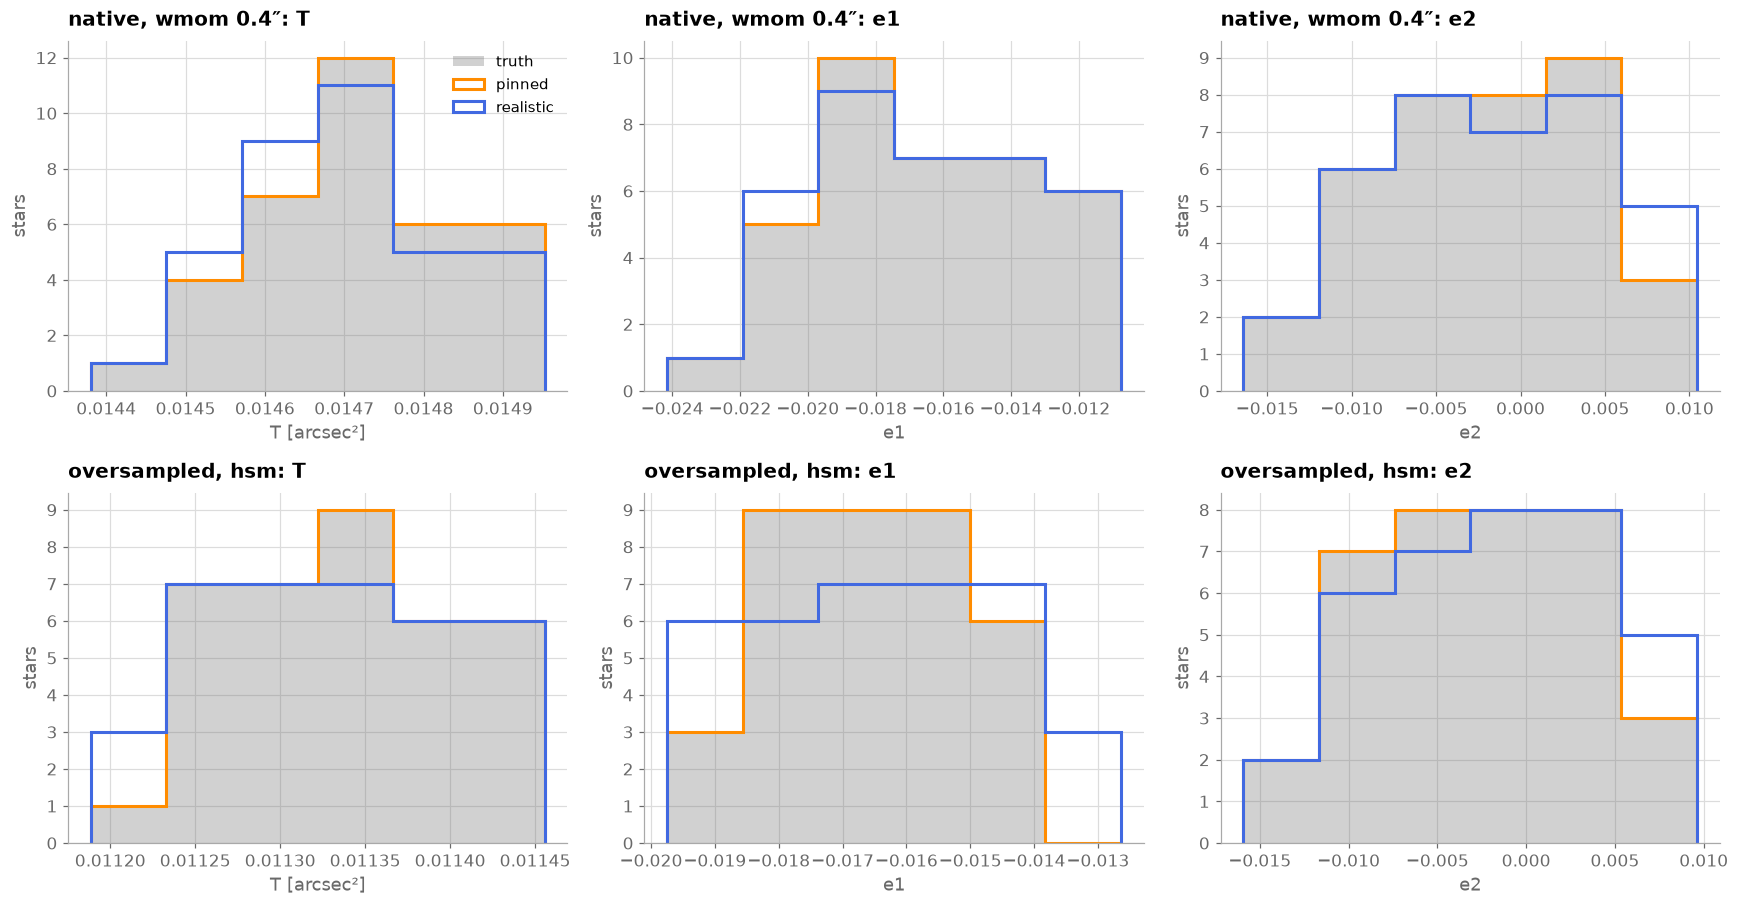

In [10]:
plot_moments(fits)
plt.show()

**Mean errors.** Model − truth, `dT_T` = (T_model − T_truth) / T_truth, `de1`, `de2`, mean over
the stars ± error on the mean. `res.moment_summary()` gives the same per comparison,
algorithm and fit / reserve stars.

In [11]:
moment_errors(fits)

/tmp/ipykernel_359293/3884395944.py:10: FutureWarning: Format strings passed to MaskedConstant are ignored, but in future may error or produce different behavior
  return f"{v:.4g}" if 1e-3 <= abs(v) < 1 else f"{v:.3e}"


model,image,n,dT_T,dT_T_err,de1,de1_err,de2,de2_err
str9,str17,int64,float64,float64,float64,float64,float64,float64
pinned,"native, wmom 0.4″",36,-2.332e-09,1.542e-09,5.901e-10,1.146e-09,3.449e-10,6.122e-10
pinned,"oversampled, hsm",36,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
realistic,"native, wmom 0.4″",36,-0.002148,3.711e-05,-6.713e-05,4.803e-05,3.557e-04,9.013e-05
realistic,"oversampled, hsm",36,-0.001226,1.327e-04,1.999e-04,1.041e-04,7.243e-04,8.416e-05


# Part 2: injected PSF errors

Three simulations, each with one PSF error (`01_simulation.ipynb`) and the same stars as
above, fitted with the pinned and the realistic model:

- **aberrations**: extra Zernikes Z4 (defocus) 0.05, Z5 0.03 and Z7 0.02 waves
  (`set_zernikes`);
- **jitter**: a random-walk pointing jitter of `galsim.roman.jitter_rms` per axis
  (`add_jitter`);
- **MTF**: the charge-diffusion kernel 10 % wider than the nominal one (`set_mtf(scale=1.1)`);
  the models keep the nominal MTF.

In [12]:
def error_sim(error):
    s = make_sim()
    if error == "aberrations":
        s.set_zernikes({4: 0.05, 5: 0.03, 7: 0.02})     # Noll index: waves
    elif error == "jitter":
        s.add_jitter("random_walk")                     # default rms: galsim.roman.jitter_rms
    elif error == "MTF":
        s.set_mtf(scale=1.1)                            # default scale=1
    return s.run()


ERRORS = ["aberrations", "jitter", "MTF"]
error_fits = {}
for error in ERRORS:
    s = error_sim(error)
    error_fits[error] = {"pinned": fit(s, pinned), "realistic": fit(s, realistic)}

**Oversampled moment errors** (`truth_os`, `hsm`): mean model − truth over the stars ± error
on the mean, one group per injected error.

/tmp/ipykernel_359293/3884395944.py:10: FutureWarning: Format strings passed to MaskedConstant are ignored, but in future may error or produce different behavior
  return f"{v:.4g}" if 1e-3 <= abs(v) < 1 else f"{v:.3e}"
/tmp/ipykernel_359293/3884395944.py:10: FutureWarning: Format strings passed to MaskedConstant are ignored, but in future may error or produce different behavior
  return f"{v:.4g}" if 1e-3 <= abs(v) < 1 else f"{v:.3e}"
/tmp/ipykernel_359293/3884395944.py:10: FutureWarning: Format strings passed to MaskedConstant are ignored, but in future may error or produce different behavior
  return f"{v:.4g}" if 1e-3 <= abs(v) < 1 else f"{v:.3e}"


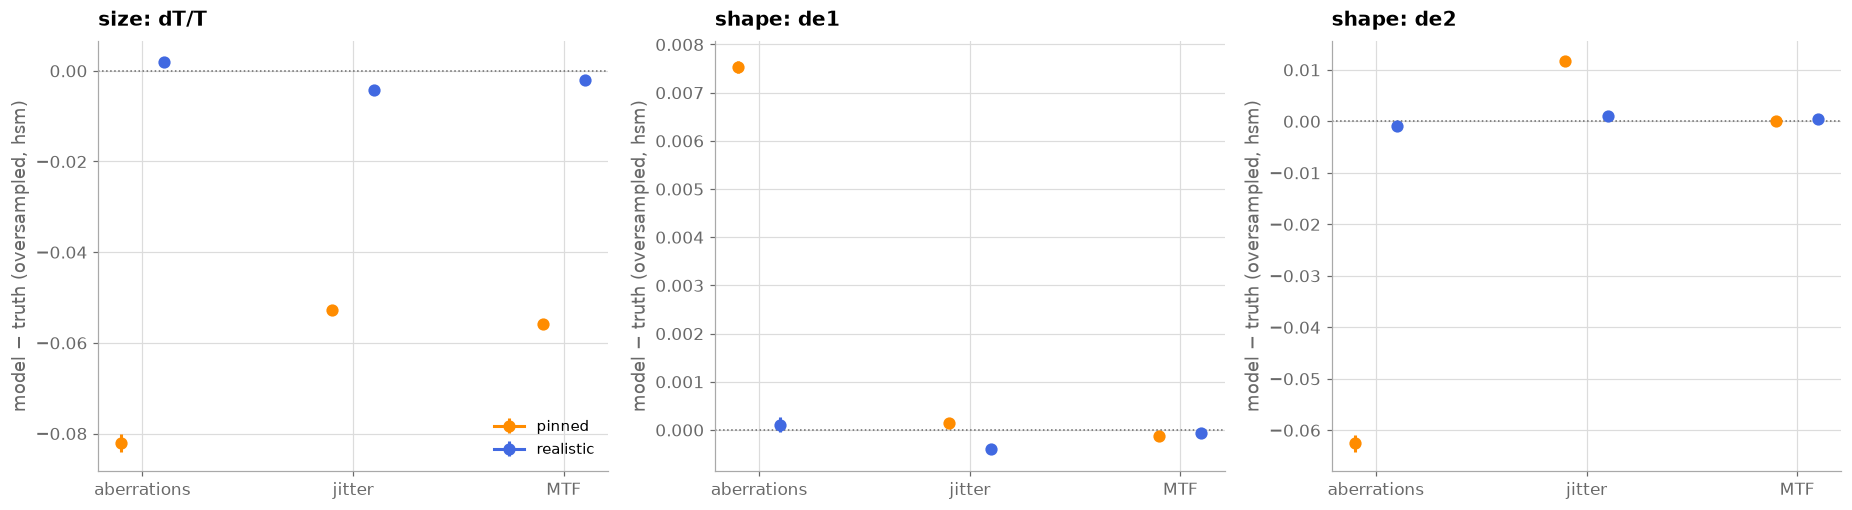

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for k, error in enumerate(ERRORS):
    t = moment_errors(error_fits[error], rows=(OVERSAMPLED,))
    for j, row in enumerate(t):
        x = k + (j - 0.5) * 0.2
        for ax, q in zip(axes, ("dT_T", "de1", "de2")):
            ax.errorbar(x, row[q], yerr=row[q + "_err"], marker="o",
                        color=MODEL_COLORS[row["model"]], label=row["model"] if k == 0 else None)
for ax, title in zip(axes, ("size: dT/T", "shape: de1", "shape: de2")):
    ax.axhline(0, color=TRUTH_COLOR, lw=1, ls=":")
    ax.set_xticks(range(len(ERRORS)), ERRORS)
    ax.set(title=title, ylabel="model − truth (oversampled, hsm)")
axes[0].legend()
fig.tight_layout()
plt.show()

The image residuals and moment distributions of one case, the aberrations:

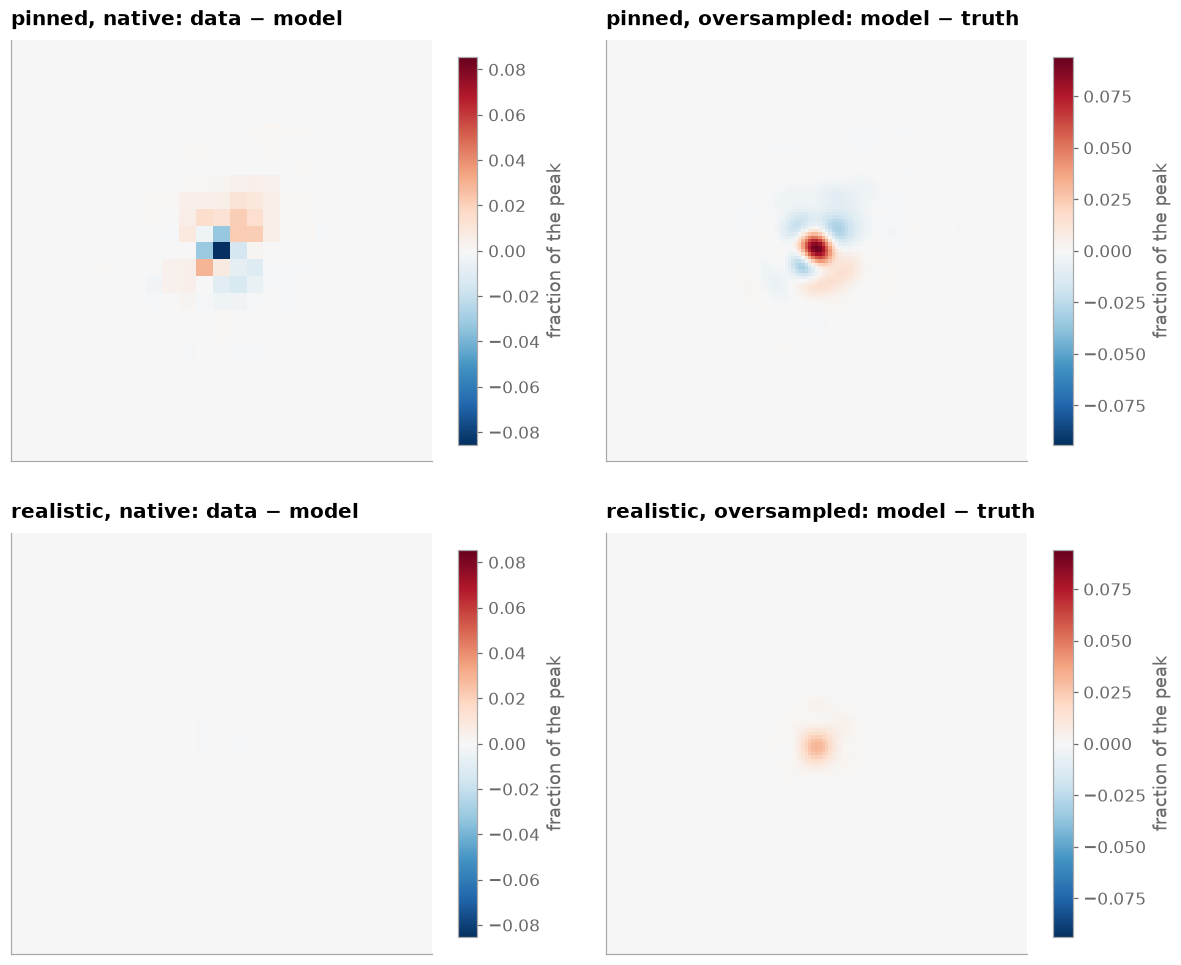

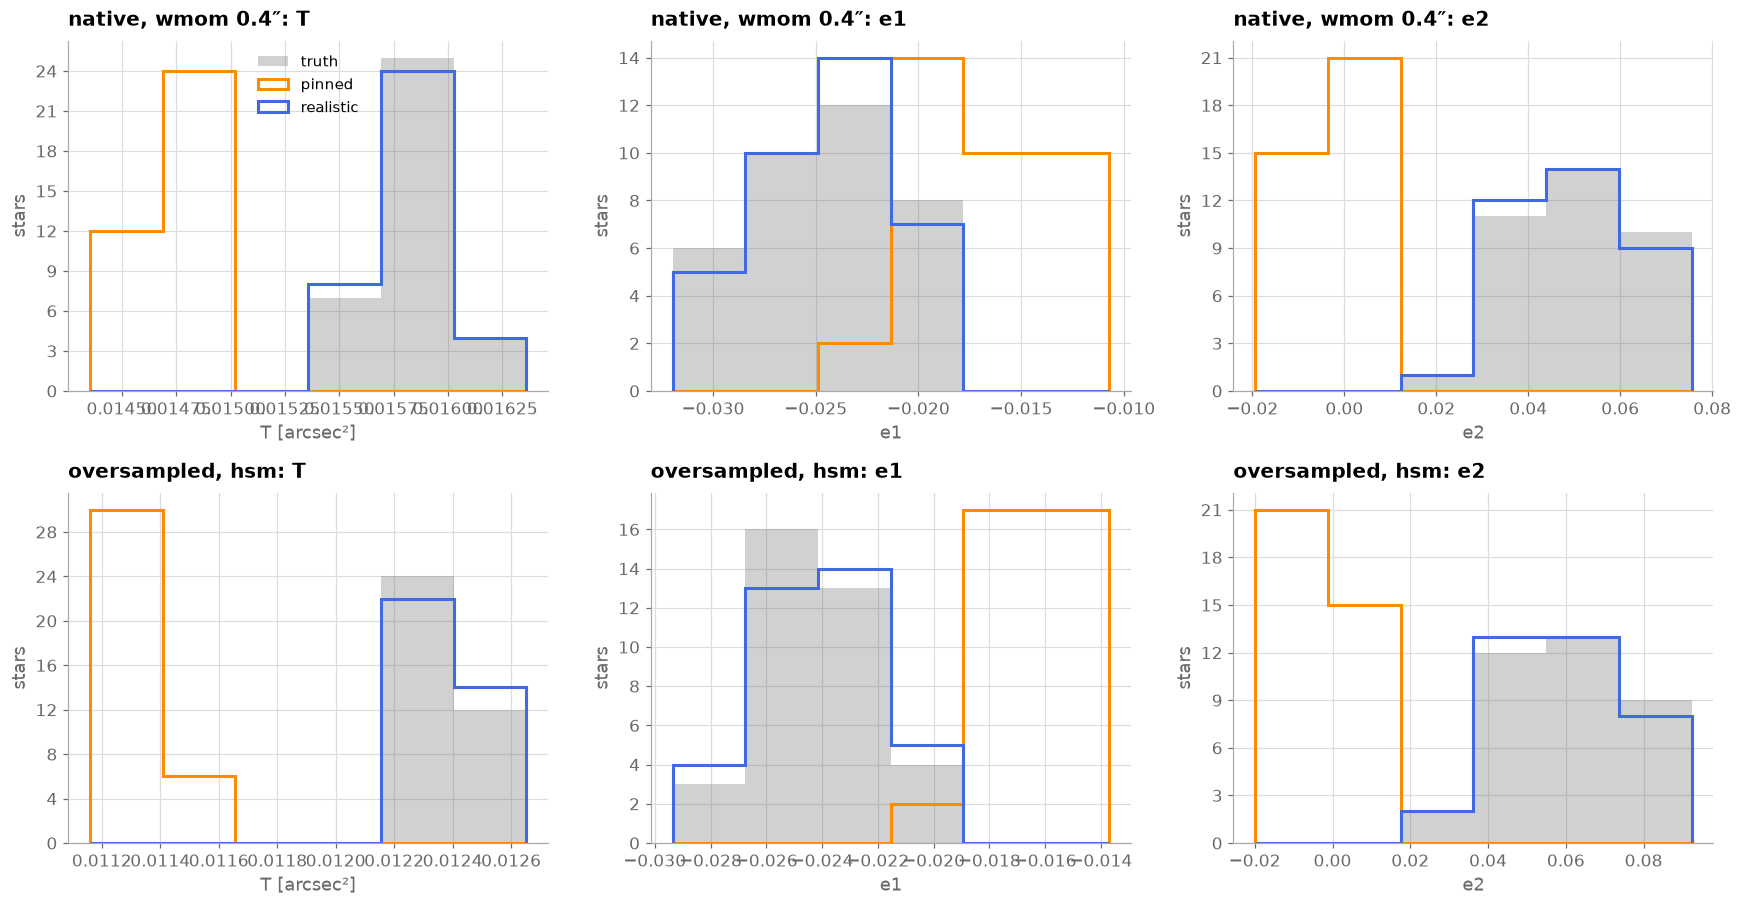

In [14]:
plot_residuals(error_fits["aberrations"])
plt.show()
plot_moments(error_fits["aberrations"])
plt.show()

**What the components fitted.** `res.components()` gives the fitted value of each component
at the stars, next to the truth where the simulation has one. The extra Zernikes of the
realistic model fitted to the aberrations (mean ± Piff's uncertainty; crosses: the injected
values):

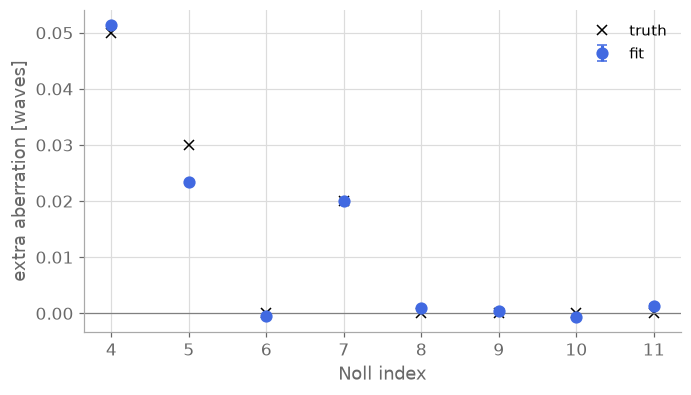

In [15]:
error_fits["aberrations"]["realistic"].plot_zernikes()
plt.show()

The second moments M (native pix²) of the `GaussianBlur` in the realistic model, mean over
the stars, for each injected error:

In [16]:
rows = []
for error in ERRORS:
    k = error_fits[error]["realistic"].components()["kernel"]
    rows.append({"error": error, "mxx": np.mean(k["mxx"]), "mxy": np.mean(k["mxy"]),
                 "myy": np.mean(k["myy"])})
fmt(Table(rows=rows))

/tmp/ipykernel_359293/3884395944.py:10: FutureWarning: Format strings passed to MaskedConstant are ignored, but in future may error or produce different behavior
  return f"{v:.4g}" if 1e-3 <= abs(v) < 1 else f"{v:.3e}"


error,mxx,mxy,myy
str11,float64,float64,float64
aberrations,0.002338,6.468e-04,0.001764
jitter,0.01303,-0.003279,0.01441
MTF,0.01457,7.524e-04,0.01478


**Each component on its own.** `plot_component_images` draws every component of the model
alone at one position (default: the SCA center), with its fitted parameters there: on the
native pixels (top) and oversampled ×5 (bottom). By default each is convolved with the native
pixel response, i.e. shown as it enters the effective PSF (`include_pixel=False` shows it
before; a `PixelGrid` always contains it). Each panel has its own color scale. Below: the
realistic model fitted to the jitter.

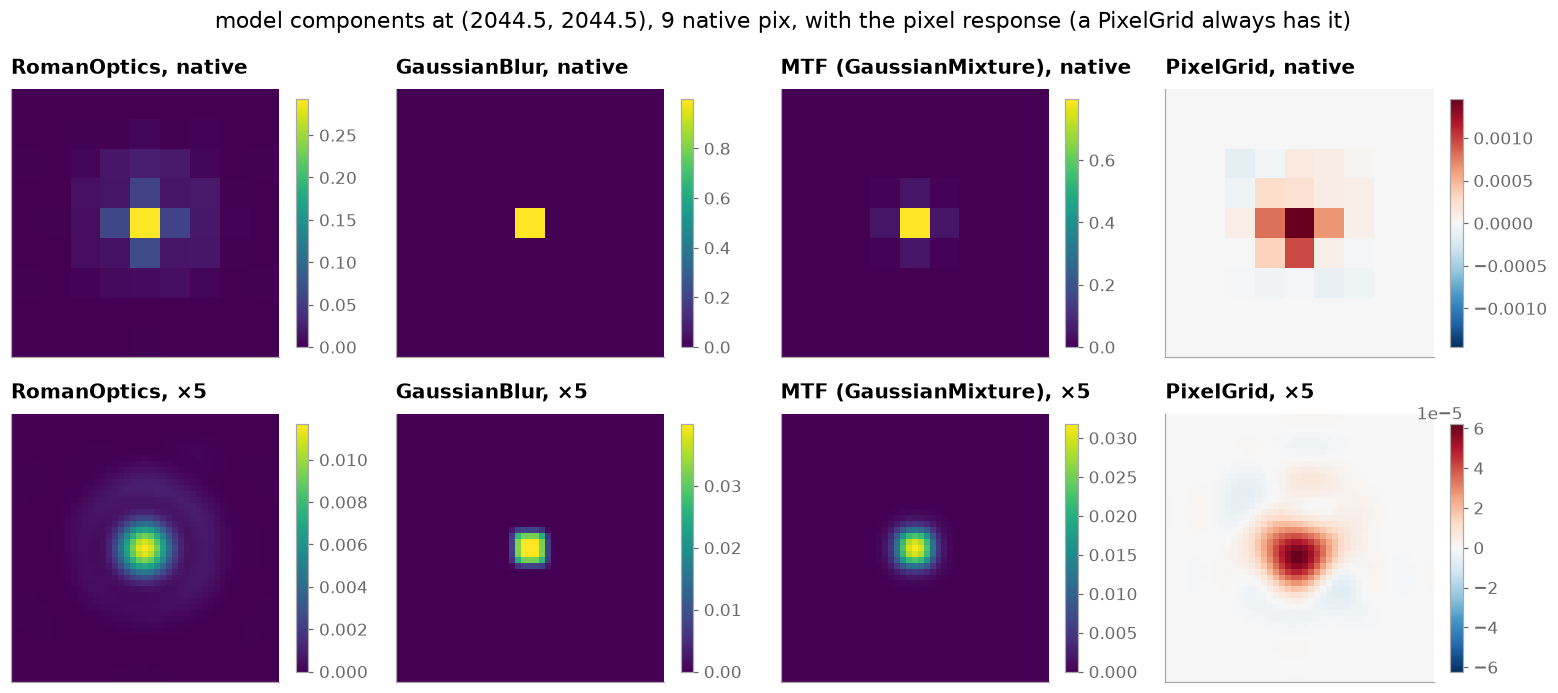

In [17]:
error_fits["jitter"]["realistic"].plot_component_images()
# defaults: x=None, y=None (SCA center), size=9 [native pix], oversample=5, include_pixel=True
plt.show()

The images themselves come from `component_image`: one component (a "leaf" of the Piff model,
from `leaf_psfs`) at one position, as a `galsim.Image`.

In [18]:
from psf_fomo.piff_simfit.components import component_image, kind_of, leaf_psfs

res = error_fits["jitter"]["realistic"]
for leaf in leaf_psfs(res.psf):                  # in the model's order
    image = component_image(res.psf, leaf, x=2044.5, y=2044.5, sca=1, oversample=5, size=9)
    # defaults: oversample=5 (1 = native pixels), size=25 [native pix], include_pixel=True
    print(f"{kind_of(leaf):9s} {leaf.model._type_name:15s} shape {image.array.shape}, "
          f"sum {image.array.sum():.4f}")

optics    Roman           shape (45, 45), sum 0.8494
kernel    GaussianBlur    shape (45, 45), sum 1.0000
mtf       GaussianMixture shape (45, 45), sum 1.0000
pixelgrid PixelGrid       shape (45, 45), sum 0.0049


## 2.1 The model across the SCA

`model_moments` measures the fitted model alone, oversampled, at any positions on the SCA (by
default the centers of a 5 × 5 grid of cells). It needs no truth, so it works for real data
too. `T`, `e1` and `e2` (`hsm`) of the realistic model fitted to the aberrations:

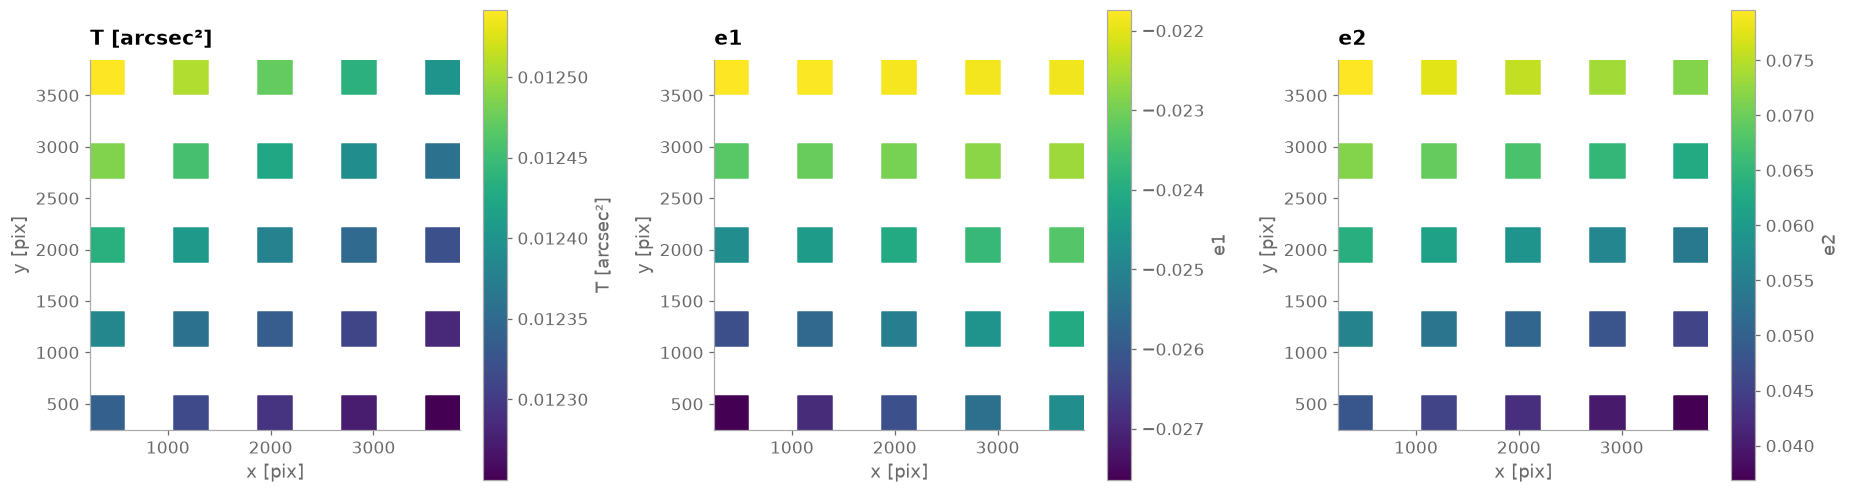

In [19]:
mm = error_fits["aberrations"]["realistic"].model_moments(n_grid=5)   # default algorithms=("hsm",)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, (q, label) in zip(axes, QUANTITIES.items()):
    sc = ax.scatter(mm["x"], mm["y"], c=mm[q], s=500, marker="s", cmap="viridis")
    fig.colorbar(sc, ax=ax, label=label)
    ax.set(title=label, xlabel="x [pix]", ylabel="y [pix]", aspect="equal")
    ax.grid(False)
fig.tight_layout()
plt.show()

## 2.2 Reference optimum

Piff fits its components one after the other, iteratively. The **reference optimum** is the
best χ² of the *same* model, with all its parameters fitted at once (fluxes profiled, star
centers held at the truth). Comparing it with Piff tells apart what Piff's fitting procedure
reaches and what the model itself can reach.

`res.reference(...)` starts from Piff's solution (`'given'`) and/or from zero kernels and
grids (`'zero'`); `freeze=("optics",)` keeps the optics at Piff's values, which makes it much
faster; `report="fit"` draws only the fit stars at the end. In the output, `"given"` is Piff's
own solution evaluated the same way (true centers, profiled fluxes). Below: the realistic
model fitted to the jitter.

In [20]:
jitter_fit = error_fits["jitter"]["realistic"]
out = jitter_fit.reference(freeze=("optics",), starts=("given", "zero"), report="fit")
# defaults: freeze=(), starts=("given",), max_nfev=50, report="all"
ref_table = comparison_table({"Piff": jitter_fit,
                              "Piff, true centers": out["given"],
                              "optimum (from Piff)": out["optimum"]["given"],
                              "optimum (from zero)": out["optimum"]["zero"]})
# comparison_table defaults: comparison="truth_os", algorithm="hsm" (fit stars)
fmt(ref_table["label", "chisq_dof", "flux_tot_r", "dT_T", "de1", "de2", "converged"])

/tmp/ipykernel_359293/3884395944.py:10: FutureWarning: Format strings passed to MaskedConstant are ignored, but in future may error or produce different behavior
  return f"{v:.4g}" if 1e-3 <= abs(v) < 1 else f"{v:.3e}"


label,chisq_dof,flux_tot_r,dT_T,de1,de2,converged
str19,float64,float64,float64,float64,float64,str4
Piff,1.0063,1.0127,-0.004268,-3.894e-04,0.001004,True
"Piff, true centers",1.0145,1.0127,-0.004268,-3.894e-04,0.001004,
optimum (from Piff),1.0083,1.0127,-0.00395,-5.773e-04,9.243e-04,True
optimum (from zero),1.0083,1.0127,-0.00395,-5.772e-04,9.244e-04,True


# Part 3: a chromatic simulation

The same stars, now drawn chromatically (the simulation default: a flat SED, each star
integrated over the filter), fitted with the same two monochromatic models. The models now
differ from the simulation in color as well. Same plots and table as in part 1.

In [21]:
chromatic_sim = make_sim(chromatic=True).run()
chromatic_fits = {"pinned": fit(chromatic_sim, pinned),
                  "realistic": fit(chromatic_sim, realistic)}

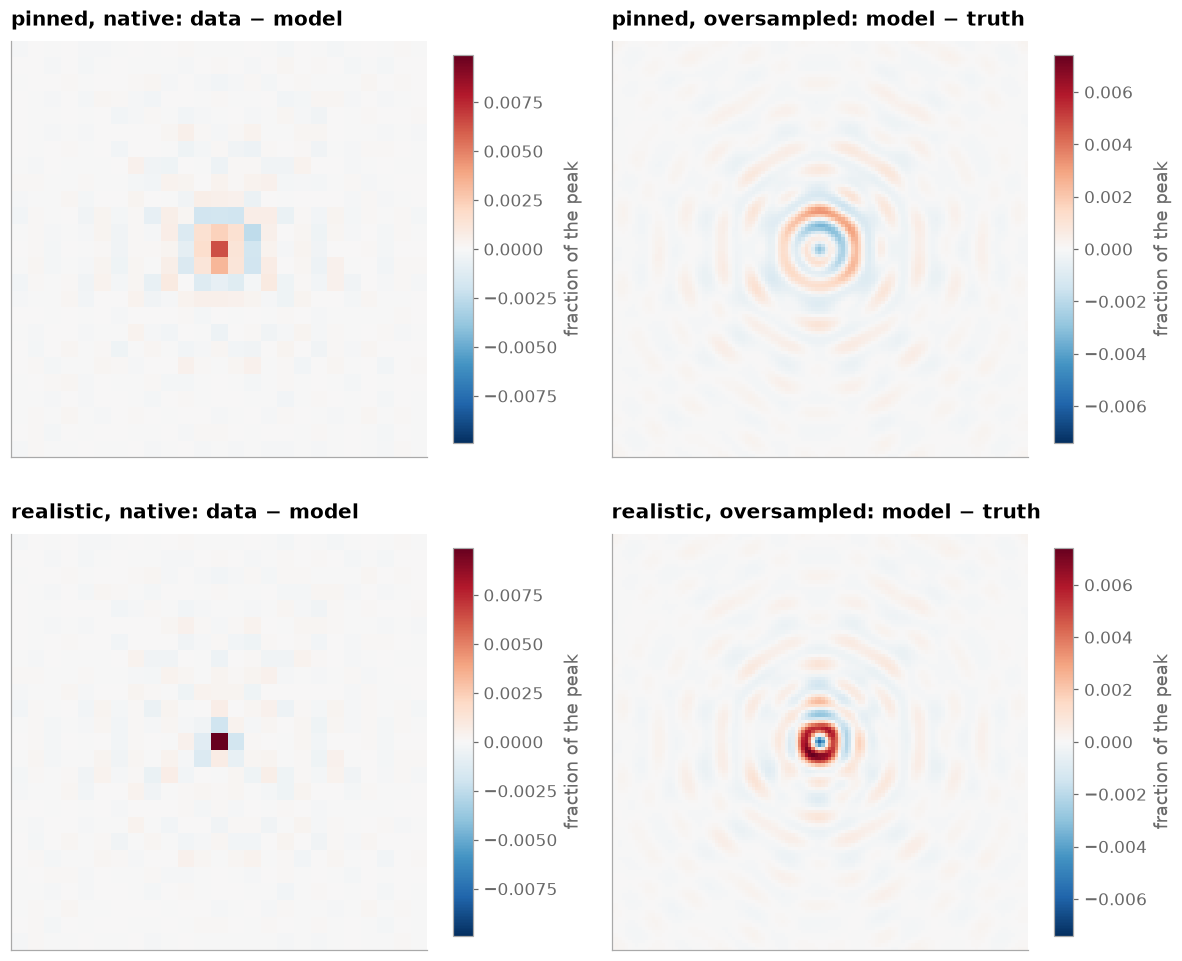

In [22]:
plot_residuals(chromatic_fits)
plt.show()

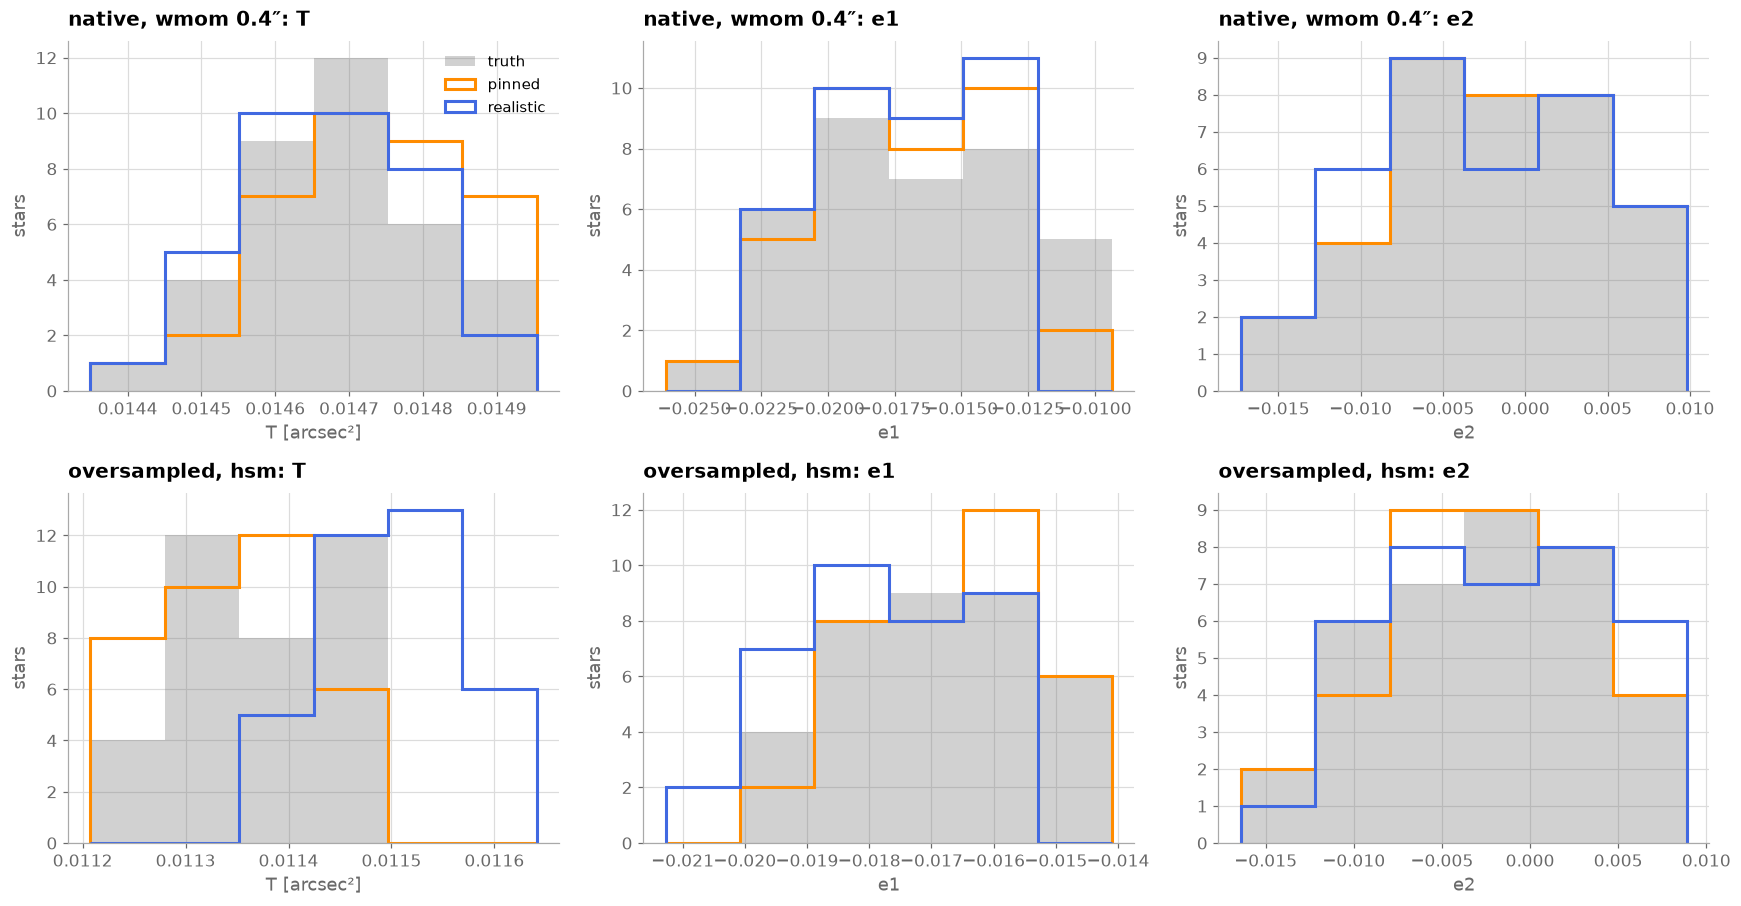

In [23]:
plot_moments(chromatic_fits)
plt.show()

In [24]:
moment_errors(chromatic_fits)

/tmp/ipykernel_359293/3884395944.py:10: FutureWarning: Format strings passed to MaskedConstant are ignored, but in future may error or produce different behavior
  return f"{v:.4g}" if 1e-3 <= abs(v) < 1 else f"{v:.3e}"


model,image,n,dT_T,dT_T_err,de1,de1_err,de2,de2_err
str9,str17,int64,float64,float64,float64,float64,float64,float64
pinned,"native, wmom 0.4″",36,0.002611,1.715e-04,3.756e-05,1.886e-04,-7.692e-05,1.181e-05
pinned,"oversampled, hsm",36,-0.00257,4.954e-05,3.318e-04,1.573e-05,1.495e-04,2.762e-05
realistic,"native, wmom 0.4″",36,-0.001053,2.106e-04,-9.363e-05,2.296e-04,-5.399e-04,8.520e-05
realistic,"oversampled, hsm",36,0.01163,4.421e-04,-8.288e-04,4.964e-05,7.253e-04,2.030e-04


## Saving, files mode, ρ statistics

A fit can be saved to a folder (Piff's `psf.fits`, the star table, moments and the settings)
and reloaded. The same fit can also run through Piff's own file input: the simulation is
saved and a Piff YAML configuration written. ρ statistics need `treecorr` and many stars. The
cells are commented out so that running the notebook writes nothing.

In [25]:
# Save while running, or afterwards, and reload:
# pv = PiffSimFit(sim, realistic, sca=1)
# res = pv.run(save_to="out/fit01")
# res.save("out/fit01")
# from psf_fomo.piff_simfit import load_sim_fit
# res = load_sim_fit("out/fit01", sim=sim)

# Through Piff's file input (one observation; writes the simulation and piff.yaml):
# res_files = PiffSimFit(sim, realistic, sca=1, obs=0).run(save_to="out/fit02", mode="files")

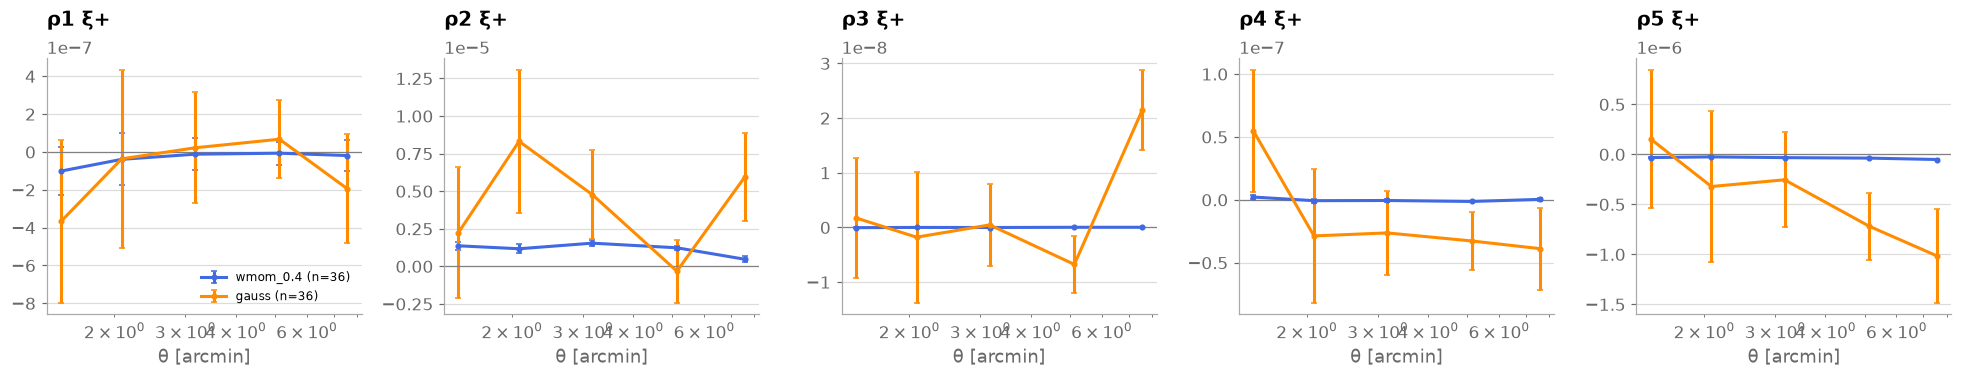

In [ ]:
# rho statistics of data − model using TreeCorr, and the plot:
rho = res.rho(algorithms=("wmom", "gauss"))
_ = res.plot_rho(rho)